# Deep Learning: Learning Beacon Heatmaps

Robot beacon localization project — Step 6. Reuses `map_gen.py`, `visibility.py`, `solvers.py`, and adds `dl_dataset.py`, `dl_model.py`, `dl_train.py`, `dl_eval.py`.

## Where a neural network fits in this problem

We already have an exact solver that produces a **provably optimal** solution in about 1.3 s per map (visibility computation, CP-SAT and constraint-generation verification included; measured in Section 4). A neural network cannot beat it on solution quality.
The meaningful question is: **can a network learn from the map's pixels what the solver has learned?** — structure such as "reflex corners are key positions"
or "narrow corridors need dedicated beacons". If it can, that is a **free prior** that can guide heuristic search,
and can also provide fast approximations on large maps where the solver cannot keep up.

**Plan**:

1. **Data**: random maps + optimal solutions verified by constraint generation, labeled automatically by the existing pipeline (472 maps)
2. **Model**: a small U-Net that takes the map raster as input and outputs, for every candidate position, the probability that "a beacon should go here" (a heatmap)
3. **Decoding**: the network output is not guaranteed to be feasible → "guided greedy + pruning + fine-grid verification" turns it into a valid layout
4. **Evaluation**: compare beacon counts against plain greedy and the ILP optimum; analyze the network's preferences across candidate types

This is the classic *neural combinatorial optimization* recipe (a network outputs a heatmap that guides the search),
but here we have an advantage others usually lack: **every map has a ground truth that is provably optimal on its sample points** (the coarse `RES=4` and fine `RES=8` points together).

In [1]:
import os
import subprocess
import sys
from math import comb

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch

from dl_dataset import GRID_H, GRID_W, RES_CHECK, RES_SOLVE, map_params, unique_candidates
from dl_eval import KINDS
from dl_model import UNet, cand_probs, guided_greedy, predict
from dl_train import split
from map_gen import make_map
from visibility import sample_points, wall_arrays

DATA, MODEL, HIST, EVAL = 'dl_data.npz', 'dl_model.pt', 'dl_model_hist.npz', 'dl_eval.npz'


def run(cmd):
    """Run a script and print its output live"""
    print('$', ' '.join(cmd))
    subprocess.run([sys.executable] + cmd, check=True)

## 1. Dataset

`dl_dataset.py` rasterizes each map at **2x resolution**: raster $(i,j)$ corresponds to world coordinate $(i/2, j/2)$,
so wall corners (integer coordinates) and wall-segment midpoints (half-integer coordinates) land exactly on raster points.

2 input channels:

- **Free-space field**: the fraction of free cells among the cells adjacent to the raster point. Cell center 1/0, wall face 0.5, **reflex corner 0.75, convex corner 0.25** — geometric information is encoded directly in the values
- **Candidate mask**: whether the point is a beacon candidate

The label is the optimal-solution mask: verified point by point on the fine `RES_CHECK = 8` grid and optimal for the coarse (`RES_SOLVE = 4`) and fine sample points together — see `refinement.ipynb` for why that is the right notion of optimality. The loss is computed only at candidate positions; other positions are meaningless.

> Generating one sample takes about 1–2 s (constraint-generation verification). The script can resume where it left off: `python dl_dataset.py --n 500 --budget 60`

samples 472  (train 376 / val 48 / test 48)
raster size 25x33  (16x12 grid at 2x resolution)
per map: area 86 cells, 135 candidates, 24.8 optimal beacons (range 13-40)
positive rate: the optimal solution is 18.4% of candidates


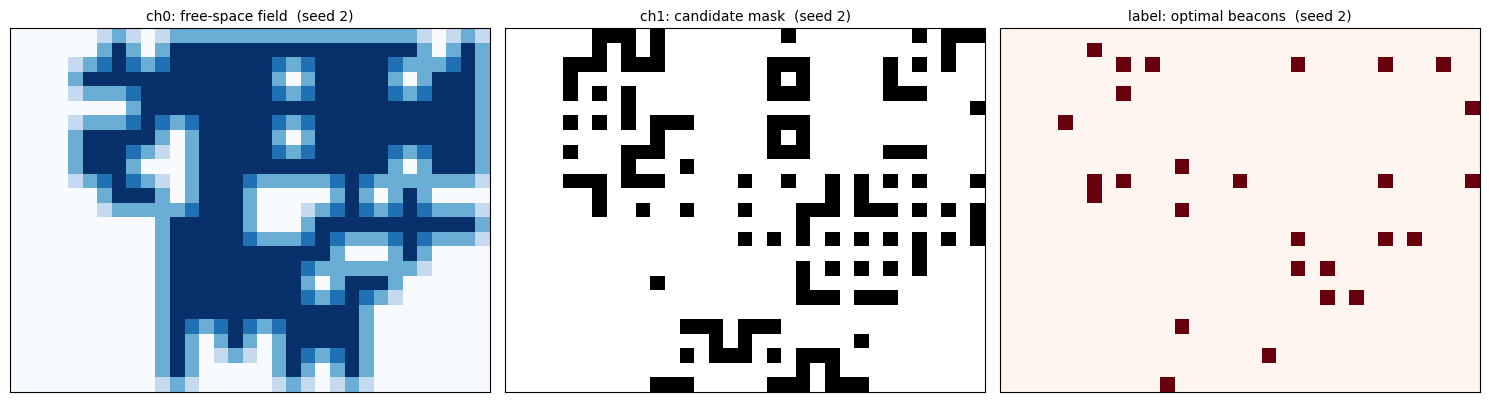

In [2]:
if not os.path.exists(DATA):
    run(['dl_dataset.py', '--n', '500', '--out', DATA])

d = np.load(DATA)
X, Y, seeds = d['X'], d['Y'], d['seed']
tr, va, te = split(seeds)
print(f'samples {len(seeds)}  (train {len(tr)} / val {len(va)} / test {len(te)})')
print(f'raster size {X.shape[2]}x{X.shape[3]}  ({GRID_W}x{GRID_H} grid at 2x resolution)')
print(f'per map: area {d["area"].mean():.0f} cells, {d["n_cand"].mean():.0f} candidates, '
      f'{d["n_beacons"].mean():.1f} optimal beacons (range {d["n_beacons"].min()}-{d["n_beacons"].max()})')
print(f'positive rate: the optimal solution is {100 * Y.sum() / X[:, 1].sum():.1f}% of candidates')

i = tr[0]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, img, title, cmap in [(axes[0], X[i, 0], 'ch0: free-space field', 'Blues'),
                             (axes[1], X[i, 1], 'ch1: candidate mask', 'Greys'),
                             (axes[2], Y[i], 'label: optimal beacons', 'Reds')]:
    ax.imshow(img, origin='lower', cmap=cmap, interpolation='nearest')
    ax.set_title(f'{title}  (seed {seeds[i]})', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 2. Model and training

**U-Net** (3 downsampling levels; the 4×5 bottleneck feature map sees the whole map). We chose it because **visibility is non-local**:
whether a position should get a beacon depends on whether distant walls block the line of sight, which needs a global receptive field.

**Regularization**: 376 training maps is very few. We use flip augmentation (horizontal/vertical flips are geometrically fully valid for this problem),
weight decay, and early stopping on validation loss. The parameter count is kept down to 120k.

**Loss**: BCE at candidate positions, with positive-class weighting (the optimal solution is only 18% of the candidates).

Validation metric **P@n**: for each map, take the $n$ candidates with the highest probability ($n$ = size of the optimal solution) and see how many are in the optimal solution. The random baseline ≈ 0.18.

parameters 121,457


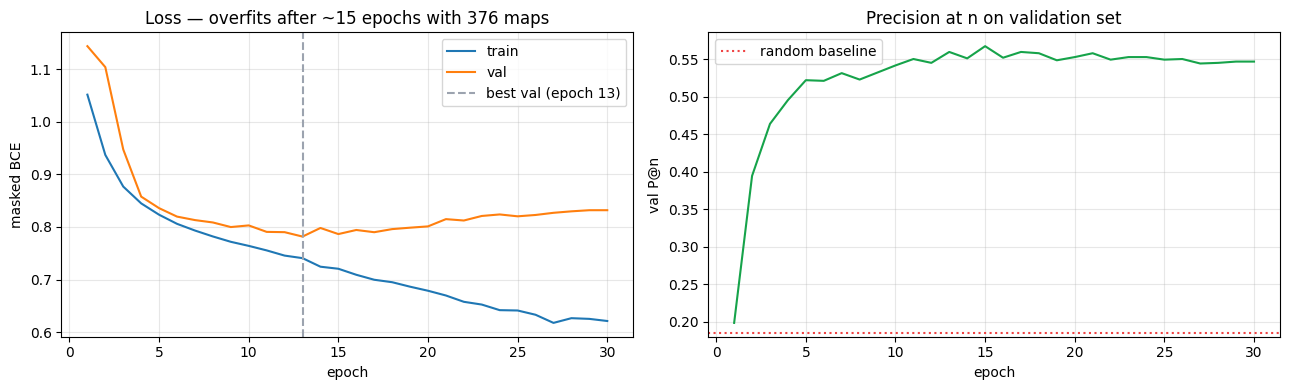

In [3]:
if not os.path.exists(MODEL):
    run(['dl_train.py', '--data', DATA, '--epochs', '30', '--base', '8', '--out', MODEL])

model = UNet(base=8)
model.load_state_dict(torch.load(MODEL, map_location='cpu'))
print(f'parameters {sum(p.numel() for p in model.parameters()):,}')

h = np.load(HIST)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ep = np.arange(1, len(h['train_loss']) + 1)
axes[0].plot(ep, h['train_loss'], label='train'); axes[0].plot(ep, h['val_loss'], label='val')
best = int(h['val_loss'].argmin()) + 1
axes[0].axvline(best, ls='--', color='#9ca3af', label=f'best val (epoch {best})')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('masked BCE'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title('Loss — overfits after ~15 epochs with 376 maps')
axes[1].plot(ep, h['val_p_at_n'], color='#16a34a')
axes[1].axhline(0.185, ls=':', color='#ef4444', label='random baseline')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('val P@n'); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title('Precision at n on validation set')
plt.tight_layout(); plt.show()

## 3. What the heatmaps look like

Test-set maps (never seen by the network). Color = predicted probability, red stars = ILP optimal solution, green circles = the layout found by hybrid decoding (gain × network probability, see Section 4).

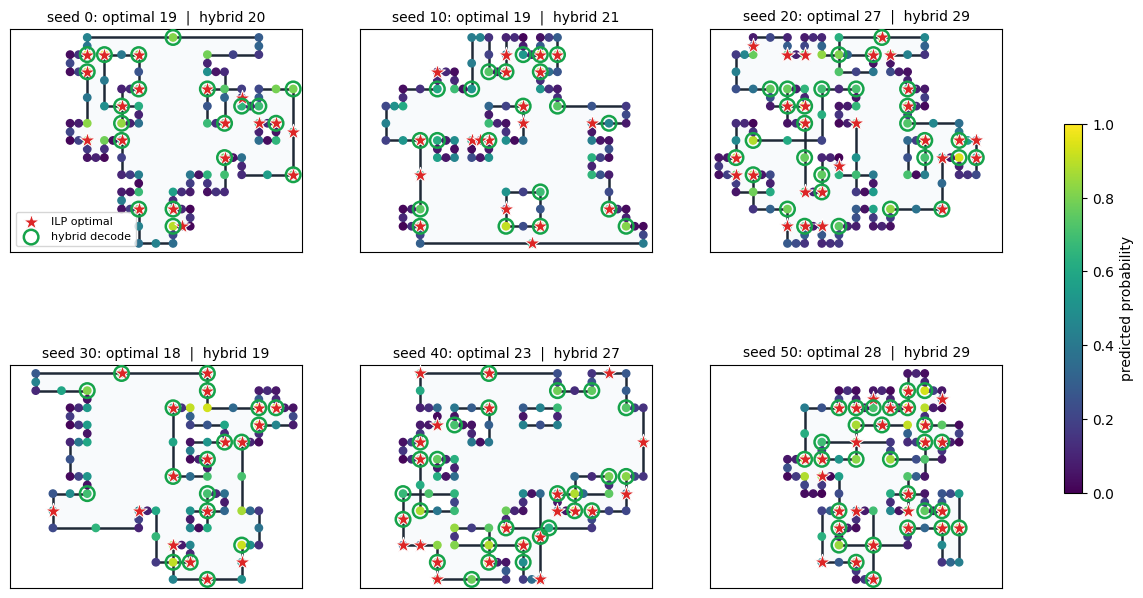

In [4]:
def draw_map(ax, cells, segs):
    for (x, y) in cells:
        ax.add_patch(Rectangle((x, y), 1, 1, facecolor='#f8fafc', edgecolor='none'))
    for (x1, y1), (x2, y2) in segs:
        ax.plot([x1, x2], [y1, y2], color='#1f2937', linewidth=1.8, zorder=3)
    ax.set_xlim(-0.5, GRID_W + 0.5); ax.set_ylim(-0.5, GRID_H + 0.5); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])


fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, i in zip(axes.flat, te[:6]):
    seed = int(seeds[i]); target, holes = map_params(seed)
    cells, segs, co, mi = make_map(GRID_W, GRID_H, target, holes, seed)
    cands = unique_candidates(co, mi); W1, W2 = wall_arrays(segs)
    prob = predict(model, X[i].astype(np.float32))
    pc = cand_probs(prob, cands)
    sol, _ = guided_greedy(cands, cells, W1, W2, sample_points(cells, RES_SOLVE),
                           sample_points(cells, RES_CHECK), scores=pc, mode='hybrid')
    draw_map(ax, cells, segs)
    C = np.array(cands)
    sc = ax.scatter(C[:, 0], C[:, 1], c=pc, cmap='viridis', vmin=0, vmax=1, s=28, zorder=4)
    opt = [c for c in cands if Y[i][int(round(2 * c[1])), int(round(2 * c[0]))] > 0.5]
    O = np.array(opt)
    ax.scatter(O[:, 0], O[:, 1], marker='*', s=140, color='#dc2626', edgecolor='white',
               linewidth=0.7, zorder=5, label='ILP optimal')
    S = C[sol]
    ax.scatter(S[:, 0], S[:, 1], s=110, facecolor='none', edgecolor='#16a34a',
               linewidth=1.8, zorder=6, label='hybrid decode')
    ax.set_title(f'seed {seed}: optimal {len(opt)}  |  hybrid {len(sol)}', fontsize=10)
axes[0, 0].legend(loc='lower left', fontsize=8)
fig.colorbar(sc, ax=axes, shrink=0.6, label='predicted probability')
plt.show()

## 4. Beacon counts after decoding: compared with greedy and optimal

A heatmap by itself is not a layout — it may leave blind spots. `guided_greedy` turns it into a valid layout:
add candidates in score order until the requirement is met, prune redundant ones, then verify on the fine grid and repair. All three scoring schemes go through **the same** pipeline, for a fair comparison:

| Method | Picked at each step |
|---|---|
| **greedy** | the candidate with the largest gain (plain greedy + pruning) |
| **nn** | among candidates with gain > 0, the one with the highest network probability |
| **hybrid** | the candidate maximizing gain × network probability |

Because all methods run on the same 48 maps, they are also compared pairwise with an exact two-sided sign test (a win = fewer beacons on a map;
ties are dropped), and the exact pipeline is timed against the decoders.

> Evaluation takes about 3 s per map (three decoders plus a timed re-run of the exact pipeline); `dl_eval.py` can resume where it left off.

48 test maps (unseen by the network)

method           mean       gap   hit opt  worst
--------------------------------------------------
optimal         24.65     +0.00      100%     +0
hybrid          26.33     +1.69       19%     +5
nn              26.79     +2.15        8%     +5
greedy          27.52     +2.88        4%     +5

mean time per map: exact 1.28s | hybrid 0.67s | nn 0.65s | greedy 0.72s

paired comparison (exact two-sided sign test):
  hybrid vs greedy: 34 wins /  9 ties /  5 losses   p = 2.4e-06
  nn     vs greedy: 31 wins /  8 ties /  9 losses   p = 6.8e-04
  hybrid vs nn    : 21 wins / 25 ties /  2 losses   p = 6.6e-05


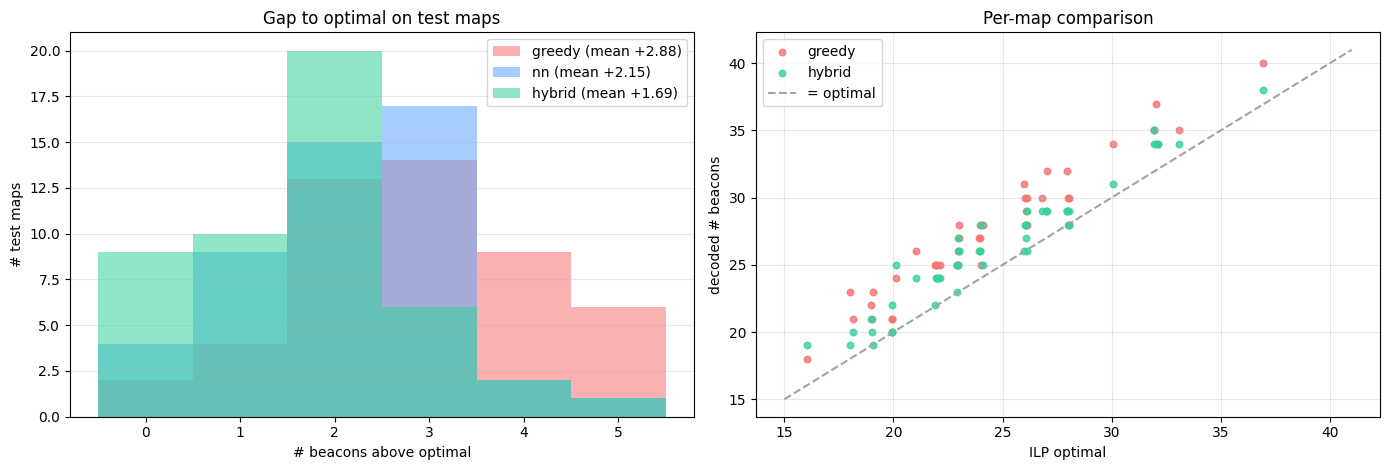

In [5]:
if not os.path.exists(EVAL):
    run(['dl_eval.py', '--data', DATA, '--model', MODEL, '--out', EVAL])

R = list(np.load(EVAL, allow_pickle=True)['results'])
opt = np.array([r['opt'] for r in R]); nn = np.array([r['nn'] for r in R])
hy = np.array([r['hybrid'] for r in R]); gr = np.array([r['greedy'] for r in R])

print(f'{len(R)} test maps (unseen by the network)\n')
print(f'{"method":<10} {"mean":>10} {"gap":>9} {"hit opt":>9} {"worst":>6}')
print('-' * 50)
for name, v in [('optimal', opt), ('hybrid', hy), ('nn', nn), ('greedy', gr)]:
    print(f'{name:<10} {v.mean():>10.2f} {(v - opt).mean():>+9.2f} '
          f'{100 * (v == opt).mean():>8.0f}% {(v - opt).max():>+6d}')

t = {k: np.mean([r[k] for r in R]) for k in ('t_opt', 't_hybrid', 't_nn', 't_greedy')}
print(f'\nmean time per map: exact {t["t_opt"]:.2f}s | hybrid {t["t_hybrid"]:.2f}s | '
      f'nn {t["t_nn"]:.2f}s | greedy {t["t_greedy"]:.2f}s')


def sign_test(a, b):
    """Exact two-sided sign test on paired beacon counts (a win = a uses fewer beacons); ties are dropped"""
    wins, losses = int((a < b).sum()), int((a > b).sum())
    n = wins + losses
    p = min(1.0, 2 * sum(comb(n, i) for i in range(min(wins, losses) + 1)) / 2 ** n)
    return wins, int((a == b).sum()), losses, p


print('\npaired comparison (exact two-sided sign test):')
for a_name, a, b_name, b in [('hybrid', hy, 'greedy', gr), ('nn', nn, 'greedy', gr), ('hybrid', hy, 'nn', nn)]:
    wins, ties, losses, p = sign_test(a, b)
    print(f'  {a_name:<6} vs {b_name:<6}: {wins:2d} wins / {ties:2d} ties / {losses:2d} losses   p = {p:.1e}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
bins = np.arange(-0.5, max((gr - opt).max(), (nn - opt).max()) + 1.5)
for v, name, col in [(gr, 'greedy', '#f87171'), (nn, 'nn', '#60a5fa'), (hy, 'hybrid', '#34d399')]:
    axes[0].hist(v - opt, bins=bins, alpha=0.55, label=f'{name} (mean +{(v - opt).mean():.2f})', color=col)
axes[0].set_xlabel('# beacons above optimal'); axes[0].set_ylabel('# test maps')
axes[0].set_title('Gap to optimal on test maps'); axes[0].legend(); axes[0].grid(alpha=0.3, axis='y')

j = np.random.default_rng(0).normal(0, 0.08, len(opt))
axes[1].scatter(opt + j, gr, s=22, color='#f87171', label='greedy', alpha=0.8)
axes[1].scatter(opt + j, hy, s=22, color='#34d399', label='hybrid', alpha=0.8)
lim = [opt.min() - 1, max(gr.max(), hy.max()) + 1]
axes[1].plot(lim, lim, '--', color='#9ca3af', label='= optimal')
axes[1].set_xlabel('ILP optimal'); axes[1].set_ylabel('decoded # beacons')
axes[1].set_title('Per-map comparison'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. What the network learned

Group all test-set candidates by position type and compare the network's mean probability with the ILP's selection rate on the same maps.
The types are those of `map_gen.cand_kind`, the same as in `analysis.ipynb` (Question 4): **reflex** and **convex** corners, wall **midpoints**,
and **pinch points** — lattice points where two free cells touch only diagonally, which sit in the middle of two crossing walls and are visible
from both free cells. If the network has learned what the solver learned, its ranking of the types should match the ILP's.

Also compute the **AUC** (can the network rank the candidates that are "in the optimal solution" ahead of the rest), overall and within each type.

overall AUC = 0.869   (random = 0.5)

kind        count   ILP rate    mean prob kind AUC
----------------------------------------------------
pinch         133      66.2%        0.777    0.562
reflex       1921      39.8%        0.698    0.736
midpoint     3078       8.0%        0.238    0.840
convex       1339       6.2%        0.171    0.829


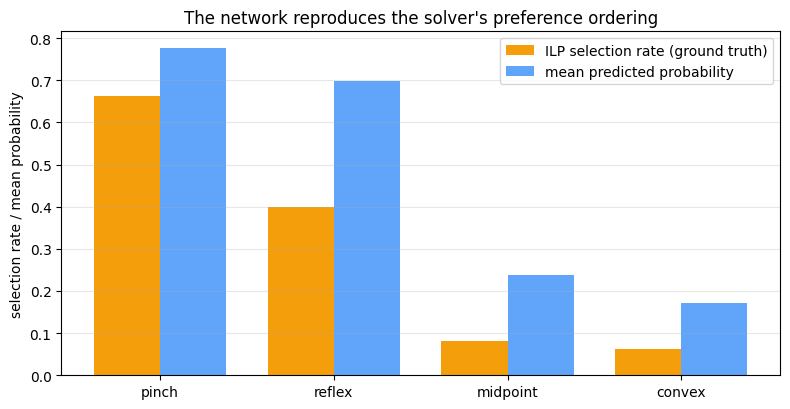

In [6]:
P = np.concatenate([r['cand_prob'] for r in R])
K = np.concatenate([r['cand_kind'] for r in R])
T = np.concatenate([r['cand_in_opt'] for r in R]).astype(bool)


def auc(score, label):
    """AUC = probability that a random positive scores higher than a random negative (rank statistic)"""
    pos, neg = score[label], score[~label]
    if len(pos) == 0 or len(neg) == 0:
        return np.nan
    return (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()


print(f'overall AUC = {auc(P, T):.3f}   (random = 0.5)\n')
print(f'{"kind":<10} {"count":>6} {"ILP rate":>10} {"mean prob":>12} {"kind AUC":>8}')
print('-' * 52)
rows = []
for ki, kn in enumerate(KINDS):
    m = K == ki
    if m.sum() == 0:
        continue
    rows.append((kn, m.sum(), T[m].mean(), P[m].mean(), auc(P[m], T[m])))
    print(f'{kn:<10} {m.sum():>6} {100 * T[m].mean():>9.1f}% {P[m].mean():>12.3f} {auc(P[m], T[m]):>8.3f}')

fig, ax = plt.subplots(figsize=(8, 4.2))
xs = np.arange(len(rows)); w = 0.38
ax.bar(xs - w / 2, [r[2] for r in rows], w, label='ILP selection rate (ground truth)', color='#f59e0b')
ax.bar(xs + w / 2, [r[3] for r in rows], w, label='mean predicted probability', color='#60a5fa')
ax.set_xticks(xs); ax.set_xticklabels([r[0] for r in rows]); ax.set_ylabel('selection rate / mean probability')
ax.set_title('The network reproduces the solver\'s preference ordering')
ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

## Summary

**The network really did learn structure.** Its ranking of the four position types — pinch points > reflex corners > wall midpoints > convex
corners — matches the ILP's selection rates exactly, and its overall AUC (0.87) is clearly above random. This is not memorization of the training
maps — it has never seen the test maps. Within a type, it separates chosen from unchosen midpoints and convex corners well (AUC 0.84 and 0.83),
reflex corners less well (0.74), and pinch points hardly at all: it rates them highly (mean probability 0.78) but can barely tell which ones
the ILP picks (AUC 0.56).

**After decoding**: pure network guidance beats plain greedy, and **hybrid scoring (gain × probability) is best** —
the gap to optimal shrinks to about 1.7 beacons, and nearly one fifth of the maps hit the optimum exactly; plain greedy manages only 4%.
The differences are not noise: on the same 48 maps hybrid beats greedy on 34 (5 losses, 9 ties; sign test p ≈ 2×10⁻⁶), nn beats greedy on 31
(p ≈ 7×10⁻⁴), and hybrid beats nn on 21 with only 2 losses (p ≈ 7×10⁻⁵). Multiplying the learned prior by the problem structure is stronger
than either one alone.

**But there is still a gap to optimal, and no real speed advantage**: the exact pipeline takes about 1.3 s per map and the decoders about 0.7 s,
because most of either time goes into computing visibility, which the decoders need as well. So at the current scale,
the network's value is **scientific** (can it learn geometric intuition? yes), not practical.

**Two honest limitations**:

- *Labels are not unique*. A map often has many equally optimal layouts, and the label is just one of them. A candidate that is not in this solution may be in another one,
  which puts a ceiling on P@n and AUC — they underestimate the network's true ability. Comparing decoded beacon counts is the fair measure.
- *Too little data*. With only 376 training maps (472 in total), the validation loss bottoms out at epoch 13 and rises afterwards. More data
  (the generator is limited only by CPU time) would almost certainly improve it further.

**To make it truly useful**, the direction is **large maps**, where the visibility matrix — the main cost of both the exact solver and the
decoders — grows with the number of candidates. One forward pass of the network is nearly free, so two uses stand out: (1) use the heatmap to
prune the candidate set to the top-K before building the visibility matrix and solving the ILP, shrinking the problem several-fold; (2) use the
heatmap as a warm start for the ILP. Both plug directly into the existing pipeline.